In [12]:
import json
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from ngram_lm import count_ngrams, train_unigram, train_bigram, train_trigram

DATA_PATH = Path("datasets/c4-train.00000-of-01024-30K.json")
MAX_DOCUMENTS = 10_000
SEED = 42
TOKEN_RE = re.compile(r"[^\W_]+(?:['’][^\W_]+)?", re.UNICODE)
SENTENCE_RE = re.compile(r"(?<=[.!?])\s+|[\r\n]+")

def split_sentences(document):
    return [tokens for part in SENTENCE_RE.split(document)
            if (tokens := TOKEN_RE.findall(part.lower()))]

with DATA_PATH.open(encoding="utf-8") as stream:
    documents = [json.loads(line)["text"] for _, line in zip(range(MAX_DOCUMENTS), stream)]

rng = np.random.default_rng(SEED)
indices = rng.permutation(len(documents))
n_train = int(0.8 * len(indices))
n_valid = int(0.1 * len(indices))
splits = {
    "train": [documents[i] for i in indices[:n_train]],
    "validation": [documents[i] for i in indices[n_train:n_train+n_valid]],
    "test": [documents[i] for i in indices[n_train+n_valid:]],
}
raw_sentences = {name: [sentence for doc in docs for sentence in split_sentences(doc)]
                 for name, docs in splits.items()}
train_counts = Counter(word for sentence in raw_sentences["train"] for word in sentence)
# Giữ từ đã xuất hiện ít nhất 2 lần để có phép đo OOV trên validation/test.
known_words = {word for word, count in train_counts.items() if count >= 2}
vocabulary = sorted(known_words | {"<unk>", "</s>"})
def map_unknown(sentences):
    return [[word if word in known_words else "<unk>" for word in sentence]
            for sentence in sentences]
corpora = {name: map_unknown(sentences) for name, sentences in raw_sentences.items()}
display(pd.DataFrame([{"split": name, "documents": len(splits[name]),
                       "sentences": len(raw_sentences[name]),
                       "tokens": sum(map(len, raw_sentences[name]))}
                      for name in splits]))
print("Vocabulary size (including <unk>, </s>):", len(vocabulary))

,split,documents,sentences,tokens
0,train,8000,165813,2888192
1,validation,1000,21384,376264
2,test,1000,20883,370479


Vocabulary size (including <unk>, </s>): 49077


## 2. Experiment 1 — Corpus statistics


,model,unique n-grams,occur once,total occurrences
0,1-gram,92344,43268,3054005
1,2-gram,1034239,758665,3054005
2,3-gram,2139927,1882546,3054005


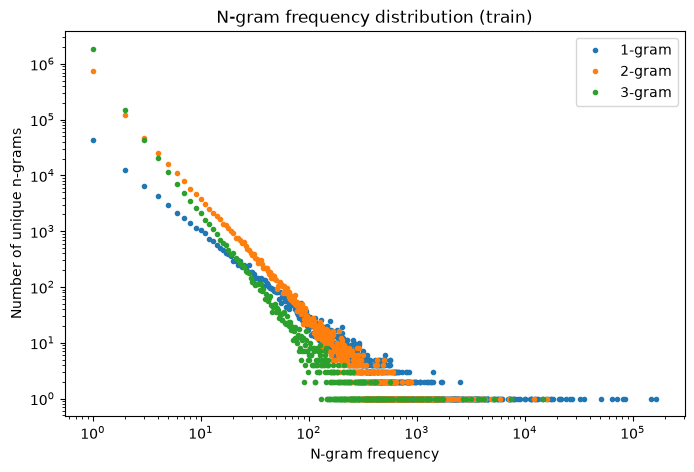

In [13]:
ngram_counts = {n: count_ngrams(raw_sentences["train"], n) for n in (1, 2, 3)}
stats = pd.DataFrame([{"model": f"{n}-gram", "unique n-grams": len(counts),
                       "occur once": sum(c == 1 for c in counts.values()),
                       "total occurrences": sum(counts.values())}
                      for n, counts in ngram_counts.items()])
display(stats)

try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Cài matplotlib để vẽ biểu đồ: python -m pip install matplotlib")
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    for n, counts in ngram_counts.items():
        frequencies = Counter(counts.values())
        ax.loglog(sorted(frequencies), [frequencies[x] for x in sorted(frequencies)],
                  marker=".", linestyle="none", label=f"{n}-gram")
    ax.set(xlabel="N-gram frequency", ylabel="Number of unique n-grams",
           title="N-gram frequency distribution (train)")
    ax.legend()
    plt.show()
del ngram_counts

## 3. Core implementation và log probability


In [14]:
class EvaluatedNGram:
    def __init__(self, n, corpus, vocabulary):
        self.n = n
        self.vocabulary = vocabulary
        self.vocab_set = set(vocabulary)
        self.model = {1: train_unigram, 2: train_bigram, 3: train_trigram}[n](corpus)
        self.counts = self.model.counts
        self.context_counts = self.model.context_counts

    def context_key(self, history):
        if self.n == 1:
            return ()
        return tuple((["<s>"] * (self.n - 1) + list(history))[-(self.n - 1):])

    def probability(self, history, word, smoothing="mle"):
        if word not in self.vocab_set:
            word = "<unk>"
        history = [w if w in self.vocab_set or w == "<s>" else "<unk>" for w in history]
        context = self.context_key(history)
        count = self.counts[context + (word,)]
        total = self.context_counts[context]
        if smoothing == "laplace":
            return (count + 1) / (total + len(self.vocabulary))
        if smoothing == "mle":
            return count / total if total else 0.0
        raise ValueError("smoothing must be 'mle' or 'laplace'")

    def sentence_log_probability(self, sentence, smoothing="mle", include_eos=True):
        words = list(sentence)
        targets = words + (["</s>"] if include_eos else [])
        logp = 0.0
        for i, word in enumerate(targets):
            p = self.probability(words[:i], word, smoothing)
            if p == 0:
                return -math.inf
            logp += math.log(p)
        return logp

    def sentence_probability(self, sentence, smoothing="mle", include_eos=True):
        return math.exp(self.sentence_log_probability(sentence, smoothing, include_eos))

    def next_word_distribution(self, history, smoothing="mle", top_k=5):
        candidates = [(word, self.probability(history, word, smoothing))
                      for word in self.vocabulary if word != "</s>"]
        return sorted(candidates, key=lambda item: (-item[1], item[0]))[:top_k]

models = {n: EvaluatedNGram(n, corpora["train"], vocabulary) for n in (1, 2, 3)}
example = split_sentences("The cat eats fish.")[0]
print("Example log P (bigram, Laplace):", models[2].sentence_log_probability(example, "laplace"))

Example log P (bigram, Laplace): -41.10013773829864


## 4. Experiment 2 — MLE vs Laplace smoothing


In [15]:
def perplexity(model, sentences, smoothing="mle"):
    total_logp = 0.0
    token_count = 0
    unseen = 0
    for sentence in sentences:
        for i, word in enumerate(sentence + ["</s>"]):
            p = model.probability(sentence[:i], word, smoothing)
            token_count += 1
            if p == 0:
                unseen += 1
            else:
                total_logp += math.log(p)
    return (math.inf if unseen else math.exp(-total_logp / token_count),
            unseen, token_count)

evaluation = []
for n in (1, 2, 3):
    for smoothing in ("mle", "laplace"):
        row = {"model": f"{n}-gram {smoothing}"}
        for split in ("train", "validation", "test"):
            ppl, unseen, total = perplexity(models[n], corpora[split], smoothing)
            row[f"{split} PPL"] = ppl
            row[f"{split} unseen"] = unseen
            row[f"{split} targets"] = total
        evaluation.append(row)
results = pd.DataFrame(evaluation)
display(results)

,model,train PPL,train unseen,train targets,validation PPL,validation unseen,validation targets,test PPL,test unseen,test targets
0,1-gram mle,1428.199669,0,3054005,1.262799e+03,0,397648,1.250396e+03,0,391362
1,1-gram laplace,1430.236765,0,3054005,1.267593e+03,0,397648,1.255208e+03,0,391362
2,2-gram mle,125.280889,0,3054005,inf,97688,397648,inf,94961,391362
3,2-gram laplace,3141.991176,0,3054005,3.886372e+03,0,397648,3.798016e+03,0,391362
4,3-gram mle,9.943303,0,3054005,inf,256986,397648,inf,250248,391362
5,3-gram laplace,12082.815988,0,3054005,2.040649e+04,0,397648,2.002870e+04,0,391362


## 5. Experiment 3 — Context length và perplexity


In [16]:
context_length = results[results["model"].str.endswith("laplace")][
    ["model", "train PPL", "validation PPL", "test PPL"]].copy()
context_length.insert(1, "unique n-grams", stats["unique n-grams"].to_numpy())
context_length["validation unseen (MLE)"] = results[
    results["model"].str.endswith("mle")]["validation unseen"].to_numpy()
context_length["test unseen (MLE)"] = results[
    results["model"].str.endswith("mle")]["test unseen"].to_numpy()
display(context_length)

,model,unique n-grams,train PPL,validation PPL,test PPL,validation unseen (MLE),test unseen (MLE)
1,1-gram laplace,92344,1430.236765,1267.592807,1255.208453,0,0
3,2-gram laplace,1034239,3141.991176,3886.372130,3798.015626,97688,94961
5,3-gram laplace,2139927,12082.815988,20406.486077,20028.704794,256986,250248


## 6. Application — Next-word prediction


In [17]:
prediction_cases = []
for sentence in corpora["test"]:
    if len(sentence) < 4:
        continue
    pos = 2
    context = sentence[:pos]
    key = tuple(context)
    if any(case["context"] == " ".join(context) for case in prediction_cases):
        continue
    top = models[2].next_word_distribution(context, "laplace", top_k=5)
    prediction_cases.append({"context": " ".join(context),
                             "prediction": top[0][0],
                             "actual next word": sentence[pos],
                             "probability": top[0][1],
                             "top 5": top})
    if len(prediction_cases) == 5:
        break
display(pd.DataFrame(prediction_cases))

,context,prediction,actual next word,probability,top 5
0,america’s best,to,colleges,0.002087,"[(to, 0.0020867145838163693), (of, 0.001990107..."
1,this ranking,in,is,0.000142,"[(in, 0.00014246173884728102), (and, 0.0001017..."
2,what does,not,the,0.012246,"[(not, 0.012245786183429612), (it, 0.001820052..."
3,if you,can,first,0.040847,"[(can, 0.04084652758679396), (are, 0.024397909..."
4,over the,<unk>,past,0.014147,"[(<unk>, 0.014147287803346115), (most, 0.00797..."


## 7. Application — Sentence ranking

In [18]:
context = split_sentences("machine learning")[0]
candidate_texts = ["is useful for NLP", "banana computer quickly", "studies language models"]
def continuation_score(model, context, continuation, smoothing="laplace"):
    words = [w if w in model.vocab_set else "<unk>" for w in continuation]
    prefix = [w if w in model.vocab_set else "<unk>" for w in context]
    total = 0.0
    for word in words + ["</s>"]:
        total += math.log(model.probability(prefix, word, smoothing))
        prefix.append(word)
    return total / (len(words) + 1)

ranking = []
for candidate in candidate_texts:
    continuation = split_sentences(candidate)[0]
    ranking.append({"context": " ".join(context), "continuation": candidate,
                    "mean log probability": continuation_score(models[3], context, continuation)})
display(pd.DataFrame(ranking).sort_values("mean log probability", ascending=False))

,context,continuation,mean log probability
0,machine learning,is useful for NLP,-9.561877
1,machine learning,banana computer quickly,-10.801299
2,machine learning,studies language models,-10.801299
